In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys
sys.path.append('/media/dll-1/SSD 4TB/code/REEDNet/')  # Replace with real path
from EEGDataLoader import EEGDataset
from models.REEDNetModel import REEDNetModel
import config
from train_eval import eval, train

model_saving_name = "/media/dll-1/SSD 4TB/EEG Datasets/experiment/nouman_conv_2/model/weights/conv_tt_012.pt"

# epochs = 50
epochs = 5
batch_size = 64
hidden_size = 20
output_size = 3  # Binary classification
number_of_eeg_channels = 1
eval_batch = 1
threshold = 0.495
active_branches = [0,1,2]

/home/anaconda/anaconda3/envs/braindecode/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_dataset = EEGDataset(config.train_data_csv, number_of_eeg_channels=number_of_eeg_channels)
val_dataset = EEGDataset(config.val_data_csv, number_of_eeg_channels=number_of_eeg_channels)
test_dataset = EEGDataset(config.test_data_csv, number_of_eeg_channels=number_of_eeg_channels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)#, collate_fn=collate)
val_loader = DataLoader(val_dataset, batch_size=eval_batch, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=eval_batch, shuffle=False)

In [ ]:
input = train_dataset.__getitem__(0)
input_x1 = input[1].shape
input_x2 = input[2].shape
input_x3 = input[3].shape
criterion = nn.CrossEntropyLoss()

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

print(input_x1,input_x2,input_x3)
input_channels_list = [input_x1[1], input_x2[1], input_x3[1]]

model = REEDNetModel(input_channels_list=input_channels_list, output_size=3)

main_output, aux_outputs = model([input[1], input[2], input[3]], active_branch_indices=active_branches)
print("Output shape:", main_output.shape) 

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001,betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:57: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at ../aten/src/ATen/native/Copy.cpp:305.)
  coefficients_cmor = torch.tensor(coefficients_cmor, dtype=torch.float32)
/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


torch.Size([1, 1, 400]) torch.Size([1, 33, 14]) torch.Size([1, 30, 400])
Output shape: torch.Size([1, 3])


ConvParallelEEG1DModel(
  (branches): ModuleList(
    (0): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(in_features=32, out_features=3, bias=True)
    )
    (1): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(33, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(

Found sample with label 1 at index 1


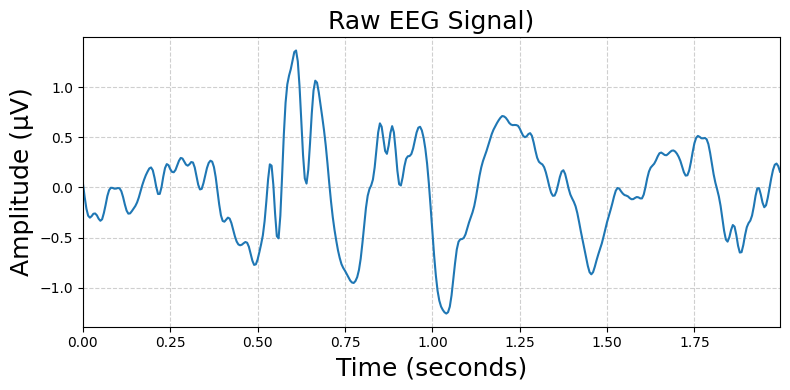

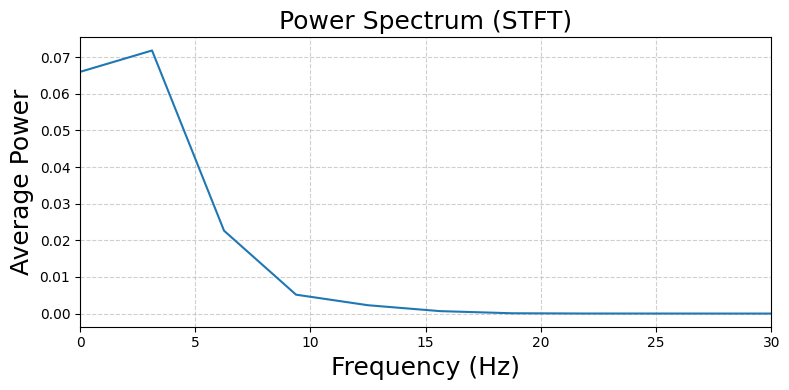

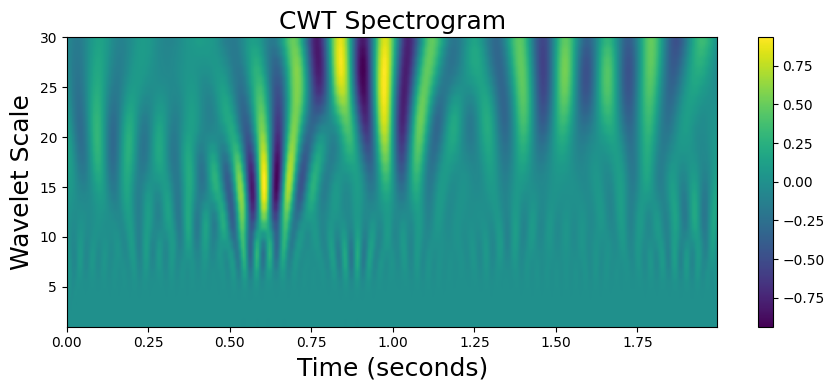

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# --- Configuration ---
sampling_rate = 200  # Hz
target_label = 1     # Change to 0, 1, or 2
font_size = 18
label_font_size = 18
figsize = (8, 4)     # Ensures same width for all plots
figsize1 = (9, 4)     # Ensures same width for all plots

# --- Search for sample with target label ---
for idx in range(len(test_dataset)):
    file_name, raw_sample_dl, stft_sample_dl, cwt_sample_dl, label_sample = test_dataset[idx]
    true_label = int(label_sample.item())

    if true_label == target_label:
        print(f"Found sample with label {true_label} at index {idx}")
        
        # Extract data
        raw_signal = raw_sample_dl.squeeze().cpu().numpy()
        stft_spectrogram = stft_sample_dl.squeeze().cpu().numpy()
        wavelet_spectrogram = cwt_sample_dl.squeeze().cpu().numpy()

        # Derived data
        time_axis = np.arange(raw_signal.shape[0]) / sampling_rate
        freqs = np.linspace(0, sampling_rate / 2, stft_spectrogram.shape[0])
        power_spectrum = stft_spectrogram.mean(axis=1)

        # --- Plot Raw EEG ---
        plt.figure(figsize=figsize)
        plt.plot(time_axis, raw_signal)
        plt.title(f"Raw EEG Signal)", fontsize=font_size)
        plt.xlabel("Time (seconds)", fontsize=label_font_size)
        plt.ylabel("Amplitude (µV)", fontsize=label_font_size)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.xlim(time_axis[0], time_axis[-1])  # Align width
        plt.tight_layout()
        plt.show()

        # --- Plot STFT Power Spectrum ---
        plt.figure(figsize=figsize)
        plt.plot(freqs, power_spectrum)
        plt.title(f"Power Spectrum (STFT)", fontsize=font_size)
        plt.xlabel("Frequency (Hz)", fontsize=label_font_size)
        plt.ylabel("Average Power", fontsize=label_font_size)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.xlim(0, 30)  # Zoom into relevant frequency band
        plt.tight_layout()
        plt.show()

        # --- Plot Wavelet Spectrogram ---
        plt.figure(figsize=figsize1)
        plt.imshow(
            wavelet_spectrogram,
            aspect='auto',
            origin='lower',
            cmap='viridis',
            extent=[time_axis[0], time_axis[-1], 1, wavelet_spectrogram.shape[0]]
        )
        plt.title(f"CWT Spectrogram", fontsize=font_size)
        plt.xlabel("Time (seconds)", fontsize=label_font_size)
        plt.ylabel("Wavelet Scale", fontsize=label_font_size)
        plt.colorbar()
        plt.tight_layout()
        plt.show()

        break  # Stop after one match
